# Mini Project 2.1 — Free-Space Path Loss and Digital Modulation Performance

**Course:** Mobile Communications — Unit 2 Lab
**Tools:** Python 3, NumPy, SciPy (`scipy.special.erfc`), Matplotlib. Pure software simulation, no SDR hardware.

**Objective.** Implement the Friis free-space equation and the Shannon–Hartley theorem, and use a Monte Carlo
simulation to measure the bit error rate (BER) of BPSK and 16-QAM over an AWGN channel. The goal is to connect
the theoretical capacity bound to an error-rate curve measured on a real modulation scheme.

The notebook follows the lab manual in order:

| Section | Manual reference |
|---|---|
| 1 | Procedure step 1 — imports and seed |
| 2 | Part (a), steps 2–5 — Friis received power and the 6 dB-per-doubling check |
| 3 | Part (b), steps 6–12 — bitstream, mappers, AWGN channel, Eb/N0 sweep, BER plot |
| 4 | Steps 13–14 — SNR gap at BER = 10⁻³ and the Shannon–Hartley explanation |
| 5 | Lab Tasks 1–6 |
| 6 | Deliverable checklist |

## 1. Setup (Procedure step 1)
Import NumPy, Matplotlib and `scipy.special`, and fix the random seed so every run gives the same numbers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special
from scipy.special import erfc
import os

np.random.seed(0)                      # step 1: reproducible results
FIG_DIR = "figures_2_1"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("NumPy", np.__version__)

NumPy 2.5.3


## 2. Part (a) — Friis free-space path loss

$$P_{RX}(\text{dBm}) = P_{TX}(\text{dBm}) + G_{TX}(\text{dBi}) + G_{RX}(\text{dBi}) - 20\log_{10}(d_{km}) - 20\log_{10}(f_{MHz}) - 32.44$$

### Step 2 — the `friis_rx_power` function
It works element-wise, so `d_km` (or `f_MHz`) can be a whole NumPy array.

In [2]:
def friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, d_km, f_MHz):
    # Received power in dBm from the Friis free-space equation (d in km, f in MHz).
    d_km = np.asarray(d_km, dtype=float)
    f_MHz = np.asarray(f_MHz, dtype=float)
    return Ptx_dBm + Gtx_dBi + Grx_dBi - 20*np.log10(d_km) - 20*np.log10(f_MHz) - 32.44

# quick sanity value: 43 dBm, 15 dBi, 0 dBi, 1 km, 900 MHz
print(f"P_RX(1 km, 900 MHz) = {friis_rx_power(43, 15, 0, 1.0, 900):.2f} dBm")

P_RX(1 km, 900 MHz) = -33.52 dBm


### Step 3 — distance vector and carrier frequencies
### Step 4 — compute and plot P_RX(d) with P_TX = 43 dBm, G_TX = 15 dBi, G_RX = 0 dBi
The left plot uses a linear distance axis, as the manual asks. The right plot shows the same curves on a
logarithmic distance axis, where the Friis law becomes a straight line (expected observation 1).

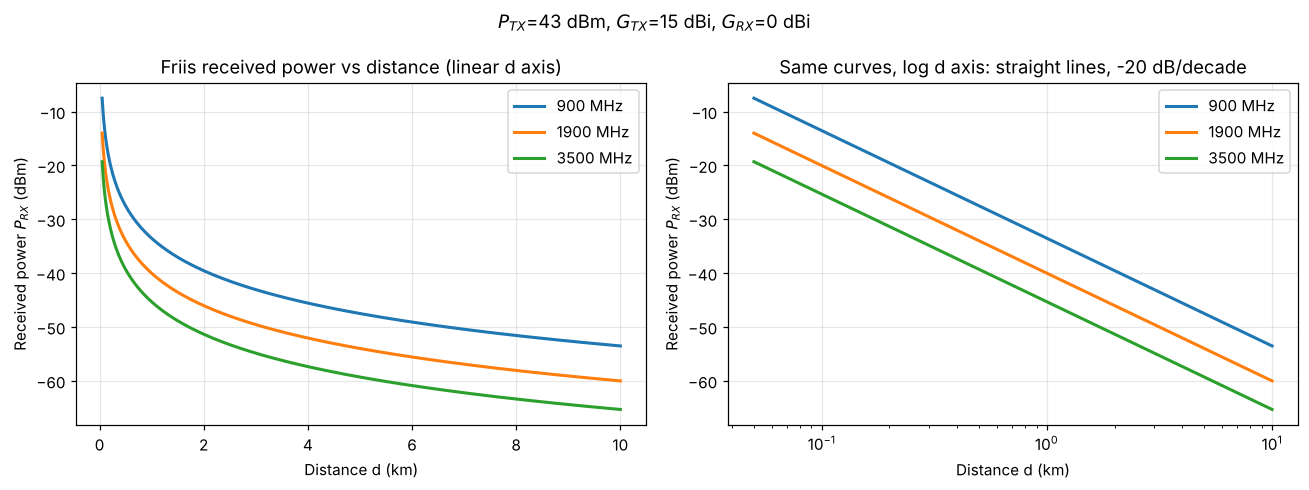

  900 MHz: P_RX at 0.05 km =   -7.50 dBm, at 10 km =  -53.52 dBm
 1900 MHz: P_RX at 0.05 km =  -13.99 dBm, at 10 km =  -60.02 dBm
 3500 MHz: P_RX at 0.05 km =  -19.30 dBm, at 10 km =  -65.32 dBm


In [3]:
# Step 3
d_km = np.linspace(0.05, 10, 500)
freqs_MHz = [900, 1900, 3500]

# Step 4
Ptx_dBm, Gtx_dBi, Grx_dBi = 43, 15, 0
Prx = {f: friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, d_km, f) for f in freqs_MHz}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xscale in zip(axes, ["linear", "log"]):
    for f in freqs_MHz:
        ax.plot(d_km, Prx[f], lw=2, label=f"{f} MHz")
    ax.set_xscale(xscale)
    ax.set_xlabel("Distance d (km)")
    ax.set_ylabel("Received power $P_{RX}$ (dBm)")
    ax.legend()
axes[0].set_title("Friis received power vs distance (linear d axis)")
axes[1].set_title("Same curves, log d axis: straight lines, -20 dB/decade")
fig.suptitle(f"$P_{{TX}}$={Ptx_dBm} dBm, $G_{{TX}}$={Gtx_dBi} dBi, $G_{{RX}}$={Grx_dBi} dBi")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/friis_rx_power_vs_distance.png", bbox_inches="tight")
plt.show()

for f in freqs_MHz:
    print(f"{f:>5} MHz: P_RX at 0.05 km = {Prx[f][0]:7.2f} dBm, at 10 km = {Prx[f][-1]:7.2f} dBm")

### Step 5 — verify the 6 dB-per-doubling rule numerically
Pick two distances a factor of two apart and subtract the received powers. Then repeat by doubling the frequency at a fixed distance.
Theory: $20\log_{10}(2) = 6.0206$ dB.

In [ ]:
theory = 20*np.log10(2)
print(f"Theoretical loss per doubling: 20*log10(2) = {theory:.4f} dB\n")

print("Doubling DISTANCE (f fixed):")
for f in freqs_MHz:
    for d1 in [0.5, 1.0, 2.5]:
        p1 = friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, d1, f)
        p2 = friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, 2*d1, f)
        print(f"  f={f:>4} MHz, d: {d1:>4} km -> {2*d1:>4} km : P_RX drops by {p1-p2:.4f} dB")

print("\nDoubling FREQUENCY (d fixed = 1 km):")
for f1 in [900, 1750, 3500]:
    p1 = friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, 1.0, f1)
    p2 = friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, 1.0, 2*f1)
    print(f"  d=1 km, f: {f1:>4} MHz -> {2*f1:>4} MHz : P_RX drops by {p1-p2:.4f} dB")

# also check it directly on the plotted array (sample nearest to 2 km and 4 km)
i2, i4 = np.argmin(abs(d_km-2)), np.argmin(abs(d_km-4))
print(f"\nFrom the plotted 1900 MHz array: d={d_km[i2]:.3f} km vs d={d_km[i4]:.3f} km "
      f"(ratio {d_km[i4]/d_km[i2]:.3f}) -> difference {Prx[1900][i2]-Prx[1900][i4]:.3f} dB")

: 

## 3. Part (b) — Monte Carlo BER of BPSK and 16-QAM over AWGN

### Step 6 — random bitstream
$N = 1.2\times10^6$ bits. The value is divisible by 1, 2, 4 and 6, so the same stream can feed BPSK, QPSK, 16-QAM and 64-QAM (64-QAM is used in Lab Task 3).
With $10^6$ bits, BER values down to about $10^{-5}$ are measured with tens of errors.

In [5]:
N = 1_200_000
bits = np.random.randint(0, 2, size=N)          # step 6
print("bits:", bits[:16], "...  ones fraction =", bits.mean().round(4))

bits: [0 1 1 0 1 1 1 1 1 1 1 0 0 1 0 0] ...  ones fraction = 0.4994


### Step 7 — mappers
* **BPSK:** bit 0 → −1, bit 1 → +1.
* **Gray-coded square M-QAM** (written generally so it also covers QPSK and 64-QAM): each group of $\log_2 M$ bits is split in half.
  The first half chooses the in-phase level and the second half the quadrature level. Each half is a Gray code that is converted to a level index,
  so neighbouring levels differ by exactly one bit. For 16-QAM the levels are −3, −1, +1, +3. The constellation is then normalised to unit average
  symbol energy, $E_s = 1$ (divide by $\sqrt{10}$ for 16-QAM).

16-QAM average symbol energy: 1.0
16-QAM I levels (x sqrt(10)): [-3 -1  1  3]
Every pair of nearest neighbours differs by exactly 1 bit: True


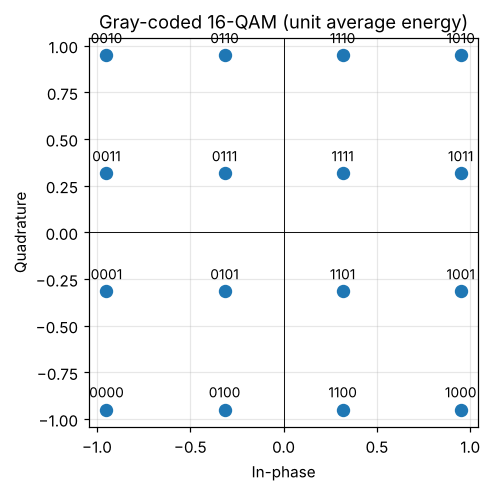

In [6]:
def bpsk_map(b):
    return (2*b - 1).astype(complex)          # 0 -> -1, 1 -> +1

def gray_to_binary(g):
    # Convert Gray-coded integers to plain binary integers (vectorised).
    b = g.copy()
    shift = g >> 1
    while np.any(shift):
        b ^= shift
        shift >>= 1
    return b

def bits_to_int(bmat):
    # Rows of bits (MSB first) -> integers.
    w = 1 << np.arange(bmat.shape[1]-1, -1, -1)
    return bmat @ w

def qam_constellation(M):
    # Return the 'points' array where points[i] is the symbol for bit pattern i (MSB first),
    # Gray coded per axis and normalised to unit average energy.
    k = int(np.log2(M)); h = k // 2; L = 2**h
    idx = np.arange(M)
    gi, gq = idx >> h, idx & (L-1)                # first half -> I, second half -> Q
    li = 2*gray_to_binary(gi) - (L-1)             # levels -(L-1) ... +(L-1)
    lq = 2*gray_to_binary(gq) - (L-1)
    pts = li + 1j*lq
    return pts / np.sqrt(np.mean(np.abs(pts)**2))

def qam_map(b, M):
    k = int(np.log2(M))
    pts = qam_constellation(M)
    return pts[bits_to_int(b.reshape(-1, k))]

# --- unit checks on the 16-QAM mapper ---
pts16 = qam_constellation(16)
print("16-QAM average symbol energy:", np.mean(abs(pts16)**2).round(6))
print("16-QAM I levels (x sqrt(10)):", np.unique(np.round(pts16.real*np.sqrt(10))).astype(int))
# Gray check: nearest neighbours differ in exactly one bit
dmin = np.min(abs(pts16[:, None]-pts16[None, :])[~np.eye(16, dtype=bool)])
ok = all(bin(i ^ j).count("1") == 1
         for i in range(16) for j in range(16)
         if i != j and abs(abs(pts16[i]-pts16[j]) - dmin) < 1e-9)
print("Every pair of nearest neighbours differs by exactly 1 bit:", ok)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(pts16.real, pts16.imag, s=60)
for i, p in enumerate(pts16):
    ax.annotate(format(i, "04b"), (p.real, p.imag), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_title("Gray-coded 16-QAM (unit average energy)"); ax.set_aspect("equal")
ax.set_xlabel("In-phase"); ax.set_ylabel("Quadrature")
plt.savefig(f"{FIG_DIR}/16qam_gray_constellation.png", bbox_inches="tight"); plt.show()

### Step 8 — AWGN channel
With $E_s = 1$ and $k$ bits per symbol, $E_b = E_s/k$ and $N_0 = E_b / (E_b/N_0)_{lin}$.
Complex Gaussian noise with total variance $N_0$ is added, which is $N_0/2$ per real dimension.
BPSK only uses the real axis, so only the real noise component affects its decisions. That is the correct model.

In [7]:
def awgn(symbols, EbN0_dB, bits_per_symbol, Es=1.0):
    EbN0 = 10**(EbN0_dB/10)
    N0 = (Es/bits_per_symbol) / EbN0
    noise = np.sqrt(N0/2) * (np.random.randn(*symbols.shape) + 1j*np.random.randn(*symbols.shape))
    return symbols + noise

# check: measured noise power equals N0
x = np.ones(200_000, complex)
y = awgn(x, 10, 4)
print(f"measured N0 = {np.var(y - x):.5f}, expected = {(1/4)/10:.5f}")

measured N0 = 0.02500, expected = 0.02500


### Step 9 — minimum-distance demodulator and the Eb/N0 sweep
### Step 10 — count bit errors, BER = errors / total bits
The detector compares each received sample with every constellation point and keeps the nearest one, which is the literal minimum-distance rule.
It runs in chunks to keep memory small. The Eb/N0 sweep goes from 0 to 16 dB in 1 dB steps.

In [8]:
def min_distance_demod(r, points, chunk=200_000):
    # Return the index (bit pattern) of the nearest constellation point for every sample.
    out = np.empty(r.size, dtype=np.int64)
    for s in range(0, r.size, chunk):
        rc = r[s:s+chunk]
        out[s:s+chunk] = np.argmin(np.abs(rc[:, None] - points[None, :])**2, axis=1)
    return out

def int_to_bits(idx, k):
    return ((idx[:, None] >> np.arange(k-1, -1, -1)) & 1).reshape(-1)

BPSK_POINTS = np.array([-1+0j, 1+0j])        # index 0 -> bit 0, index 1 -> bit 1

def simulate_ber(scheme, EbN0_dB_list, bits):
    # scheme: 'BPSK' or an M-QAM order (4 = QPSK, 16, 64).
    if scheme == "BPSK":
        k, pts, tx = 1, BPSK_POINTS, bpsk_map(bits)
    else:
        M = scheme; k = int(np.log2(M)); pts = qam_constellation(M); tx = qam_map(bits, M)
    ber = []
    for e in EbN0_dB_list:
        rx = awgn(tx, e, k)                                   # step 9: channel
        bhat = int_to_bits(min_distance_demod(rx, pts), k)    # step 9: demodulate -> bits
        errors = np.count_nonzero(bhat != bits)               # step 10
        ber.append(errors / bits.size)
    return np.array(ber)

EbN0_dB = np.arange(0, 17, 1)                                 # step 9 sweep
ber_bpsk = simulate_ber("BPSK", EbN0_dB, bits)
ber_16 = simulate_ber(16, EbN0_dB, bits)

print(" Eb/N0 |   BPSK BER   |  16-QAM BER")
for e, b1, b2 in zip(EbN0_dB, ber_bpsk, ber_16):
    print(f"  {e:>3} dB | {b1:11.3e}  | {b2:11.3e}")
print("\n(BER = 0 means no errors in 1.2e6 bits, i.e. BER < ~1e-6)")

 Eb/N0 |   BPSK BER   |  16-QAM BER
    0 dB |   7.857e-02  |   1.411e-01
    1 dB |   5.608e-02  |   1.188e-01
    2 dB |   3.753e-02  |   9.749e-02
    3 dB |   2.284e-02  |   7.730e-02
    4 dB |   1.259e-02  |   5.822e-02
    5 dB |   5.923e-03  |   4.179e-02
    6 dB |   2.388e-03  |   2.777e-02
    7 dB |   7.458e-04  |   1.686e-02
    8 dB |   1.825e-04  |   9.075e-03
    9 dB |   2.917e-05  |   4.413e-03
   10 dB |   2.500e-06  |   1.725e-03
   11 dB |   8.333e-07  |   6.175e-04
   12 dB |   0.000e+00  |   1.367e-04
   13 dB |   0.000e+00  |   2.500e-05
   14 dB |   0.000e+00  |   4.167e-06
   15 dB |   0.000e+00  |   0.000e+00
   16 dB |   0.000e+00  |   0.000e+00

(BER = 0 means no errors in 1.2e6 bits, i.e. BER < ~1e-6)


### Step 11 — theoretical BPSK curve as a sanity check
$\text{BER}_{BPSK} = \tfrac12\,\text{erfc}\!\left(\sqrt{E_b/N_0}\right)$.
For reference, the standard Gray-coded square-QAM approximation is also plotted for 16-QAM:
$\text{BER} \approx \frac{2(1-1/\sqrt M)}{\log_2 M}\,\text{erfc}\!\left(\sqrt{\frac{3\log_2 M}{2(M-1)}\frac{E_b}{N_0}}\right)$.

In [9]:
def ber_bpsk_theory(EbN0_dB):
    return 0.5*erfc(np.sqrt(10**(np.asarray(EbN0_dB)/10)))

def ber_mqam_theory(EbN0_dB, M):
    k = np.log2(M); g = 10**(np.asarray(EbN0_dB)/10)
    return 2*(1-1/np.sqrt(M))/k * erfc(np.sqrt(3*k*g/(2*(M-1))))

mask = ber_bpsk > 0
rel = np.abs(ber_bpsk[mask] - ber_bpsk_theory(EbN0_dB[mask])) / ber_bpsk_theory(EbN0_dB[mask])
print("Simulated vs theoretical BPSK (relative difference and number of bit errors counted):")
for e, r_, b_ in zip(EbN0_dB[mask], rel, ber_bpsk[mask]):
    print(f"  {e:>2} dB: {100*r_:6.1f} %   ({int(round(b_*N)):>6} errors)")
print("\nAgreement is within a few percent wherever ~100+ errors were counted. At 10-11 dB only 1-3 errors")
print("occur in 1.2e6 bits, so the BER estimate there is statistically unreliable; it is not a model error.")

Simulated vs theoretical BPSK (relative difference and number of bit errors counted):
   0 dB:    0.1 %   ( 94287 errors)
   1 dB:    0.4 %   ( 67292 errors)
   2 dB:    0.1 %   ( 45032 errors)
   3 dB:    0.2 %   ( 27408 errors)
   4 dB:    0.7 %   ( 15107 errors)
   5 dB:    0.5 %   (  7108 errors)
   6 dB:    0.0 %   (  2866 errors)
   7 dB:    3.5 %   (   895 errors)
   8 dB:    4.4 %   (   219 errors)
   9 dB:   13.3 %   (    35 errors)
  10 dB:   35.4 %   (     3 errors)
  11 dB:  218.9 %   (     1 errors)

Agreement is within a few percent wherever ~100+ errors were counted. At 10-11 dB only 1-3 errors
occur in 1.2e6 bits, so the BER estimate there is statistically unreliable; it is not a model error.


### Step 12 — combined BER plot (log y-axis, linear Eb/N0 axis in dB)

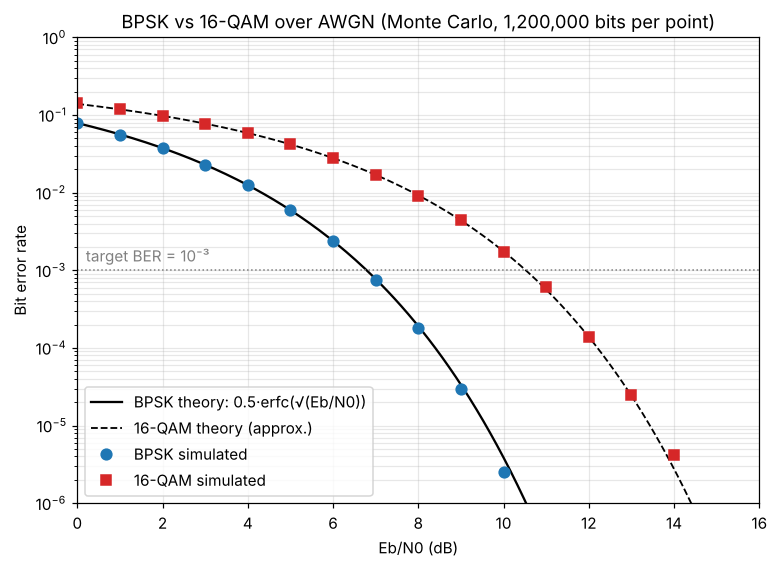

In [10]:
Efine = np.linspace(0, 16, 300)
def plot_ber(ax, x, y, **kw):
    m = y > 0                      # zero-error points cannot be shown on a log axis
    ax.semilogy(x[m], y[m], **kw)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.semilogy(Efine, ber_bpsk_theory(Efine), "k-", lw=1.5, label="BPSK theory: 0.5·erfc(√(Eb/N0))")
ax.semilogy(Efine, ber_mqam_theory(Efine, 16), "k--", lw=1.2, label="16-QAM theory (approx.)")
plot_ber(ax, EbN0_dB, ber_bpsk, marker="o", ls="none", ms=7, color="tab:blue", label="BPSK simulated")
plot_ber(ax, EbN0_dB, ber_16, marker="s", ls="none", ms=7, color="tab:red", label="16-QAM simulated")
ax.axhline(1e-3, color="gray", ls=":", lw=1)
ax.text(0.2, 1.3e-3, "target BER = 10⁻³", color="gray")
ax.set_ylim(1e-6, 1); ax.set_xlim(0, 16)
ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel("Bit error rate")
ax.set_title(f"BPSK vs 16-QAM over AWGN (Monte Carlo, {N:,} bits per point)")
ax.legend(loc="lower left"); ax.grid(True, which="both", alpha=0.3)
plt.savefig(f"{FIG_DIR}/ber_bpsk_vs_16qam.png", bbox_inches="tight"); plt.show()

## 4. Step 13 — SNR gap at a fixed target BER (10⁻³)
The Eb/N0 where each simulated curve crosses $10^{-3}$ is found by linear interpolation of $\log_{10}(\text{BER})$ between neighbouring points.
The gap is reported in two ways:
* **Eb/N0 gap** (energy per bit), which is the x-axis of the plot.
* **SNR gap** (energy per symbol, $E_s/N_0 = E_b/N_0 + 10\log_{10}k$). This is the quantity the manual's "roughly 8–10 dB" figure refers to,
  because each 16-QAM symbol carries 4 bits, so it gets $10\log_{10}4 = 6.02$ dB more energy than a BPSK symbol at the same Eb/N0.

In [11]:
def ebn0_at_ber(EbN0, ber, target=1e-3):
    m = ber > 0
    x, y = EbN0[m], np.log10(ber[m])
    i = np.where((y[:-1] >= np.log10(target)) & (y[1:] < np.log10(target)))[0][0]
    return x[i] + (np.log10(target)-y[i]) * (x[i+1]-x[i]) / (y[i+1]-y[i])

target = 1e-3
e_bpsk = ebn0_at_ber(EbN0_dB, ber_bpsk, target)
e_16 = ebn0_at_ber(EbN0_dB, ber_16, target)
gap_eb = e_16 - e_bpsk
gap_snr = (e_16 + 10*np.log10(4)) - (e_bpsk + 10*np.log10(1))

print(f"Target BER = {target:g}")
print(f"  BPSK   needs Eb/N0 = {e_bpsk:5.2f} dB  ->  SNR (Es/N0) = {e_bpsk:5.2f} dB")
print(f"  16-QAM needs Eb/N0 = {e_16:5.2f} dB  ->  SNR (Es/N0) = {e_16+10*np.log10(4):5.2f} dB")
print(f"\n  Eb/N0 gap (16-QAM - BPSK)      = {gap_eb:5.2f} dB")
print(f"  SNR (Es/N0) gap (16-QAM - BPSK) = {gap_snr:5.2f} dB")

# Shannon-Hartley view: the minimum Eb/N0 for error-free transmission at spectral efficiency eta = C/B
# follows from C = B log2(1 + SNR) with SNR = eta * Eb/N0:  Eb/N0_min = (2**eta - 1) / eta
def shannon_min_ebn0_dB(eta):
    return 10*np.log10((2.0**eta - 1)/eta)
for eta, name in [(1, "BPSK (1 b/s/Hz)"), (4, "16-QAM (4 b/s/Hz)")]:
    print(f"  Shannon limit for {name:<18}: Eb/N0 >= {shannon_min_ebn0_dB(eta):5.2f} dB, "
          f"SNR >= {10*np.log10(2.0**eta-1):5.2f} dB")
print(f"  Shannon-predicted extra SNR for 4 vs 1 b/s/Hz: {10*np.log10(15/1):.2f} dB "
      f"(extra Eb/N0: {shannon_min_ebn0_dB(4)-shannon_min_ebn0_dB(1):.2f} dB)")

Target BER = 0.001
  BPSK   needs Eb/N0 =  6.75 dB  ->  SNR (Es/N0) =  6.75 dB
  16-QAM needs Eb/N0 = 10.53 dB  ->  SNR (Es/N0) = 16.55 dB

  Eb/N0 gap (16-QAM - BPSK)      =  3.78 dB
  SNR (Es/N0) gap (16-QAM - BPSK) =  9.80 dB
  Shannon limit for BPSK (1 b/s/Hz)   : Eb/N0 >=  0.00 dB, SNR >=  0.00 dB
  Shannon limit for 16-QAM (4 b/s/Hz) : Eb/N0 >=  5.74 dB, SNR >= 11.76 dB
  Shannon-predicted extra SNR for 4 vs 1 b/s/Hz: 11.76 dB (extra Eb/N0: 5.74 dB)


### Step 14 — why the measured gap agrees with Shannon–Hartley without being predicted by it

At BER = 10⁻³, 16-QAM needs about **4 dB more Eb/N0** than BPSK, which is about **10 dB more SNR per symbol**
(see the printed numbers above). In return it carries 4 bits per symbol instead of 1, which is a four-fold increase in spectral efficiency.
Shannon–Hartley, $C = B\log_2(1+\text{SNR})$, explains why that price must be paid. Capacity grows only with the *logarithm* of SNR,
so going from 1 to 4 b/s/Hz raises the minimum SNR from $2^1-1 = 1$ (0 dB) to $2^4-1 = 15$ (11.8 dB). In Eb/N0 terms the floor rises from 0 dB to 5.7 dB.
The direction and rough size of the measured gap therefore match the theorem.

The theorem does **not** predict the exact BER numbers. It describes an ideal, infinitely long, capacity-achieving code that delivers zero errors
above the limit and fails below it. Our schemes are *uncoded*: they make independent symbol-by-symbol decisions, so their curves are smooth
"waterfalls" that sit several dB to the right of the Shannon limit (BPSK needs ~6.8 dB at 10⁻³ compared with its 0 dB limit).
The exact gap comes from constellation geometry: at equal average energy, the 16-QAM points are packed much closer together
($d_{min}^2 = 0.4\,E_s$ compared with $4\,E_s$ for BPSK), so a smaller noise sample is enough to push a point across a decision boundary.
Shannon gives the ceiling, and the modulation's geometry decides how far below that ceiling a real uncoded scheme operates.

## 5. Lab Tasks

### Lab Task 1 — add QPSK
QPSK is Gray-coded 4-QAM: two independent BPSK streams on I and Q. Its BER should land on BPSK's per-bit curve even though it carries 2 bits/symbol.

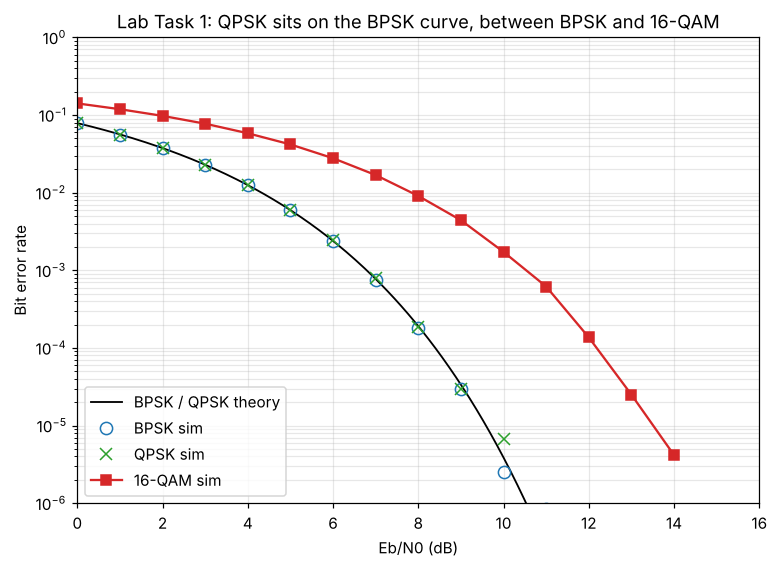

Eb/N0 at BER 1e-3:  BPSK 6.75 dB | QPSK 6.80 dB | 16-QAM 10.53 dB
QPSK - BPSK difference: +0.06 dB (essentially zero) while carrying 2x the bits/symbol


In [12]:
ber_qpsk = simulate_ber(4, EbN0_dB, bits)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.semilogy(Efine, ber_bpsk_theory(Efine), "k-", lw=1.2, label="BPSK / QPSK theory")
plot_ber(ax, EbN0_dB, ber_bpsk, marker="o", ls="none", ms=8, mfc="none", color="tab:blue", label="BPSK sim")
plot_ber(ax, EbN0_dB, ber_qpsk, marker="x", ls="none", ms=8, color="tab:green", label="QPSK sim")
plot_ber(ax, EbN0_dB, ber_16, marker="s", ls="-", ms=6, color="tab:red", label="16-QAM sim")
ax.set_ylim(1e-6, 1); ax.set_xlim(0, 16); ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel("Bit error rate"); ax.legend(loc="lower left")
ax.set_title("Lab Task 1: QPSK sits on the BPSK curve, between BPSK and 16-QAM")
plt.savefig(f"{FIG_DIR}/task1_qpsk.png", bbox_inches="tight"); plt.show()

e_q = ebn0_at_ber(EbN0_dB, ber_qpsk)
print(f"Eb/N0 at BER 1e-3:  BPSK {e_bpsk:.2f} dB | QPSK {e_q:.2f} dB | 16-QAM {e_16:.2f} dB")
print(f"QPSK - BPSK difference: {e_q-e_bpsk:+.2f} dB (essentially zero) while carrying 2x the bits/symbol")

### Lab Task 2 — rate-1/2 convolutional code with Viterbi decoding
The encoder is the industry-standard rate-1/2, constraint length $K=7$ code with generators (171, 133) in octal, which is used in 802.11a/g and many other systems.
The info bits are split into frames of 400 bits, and each frame is terminated with $K-1 = 6$ zero tail bits so it ends in state 0.
The Viterbi decoder is vectorised across all frames at once, so it stays fast in pure NumPy.

**Fair energy accounting:** each coded bit carries $E_c = R\,E_b = E_b/2$, so at the same Eb/N0 the coded transmission sees *noisier* individual bits.
Any gain that remains is real coding gain. Both hard-decision (bit decisions before decoding) and soft-decision (received values used directly) Viterbi decoders are shown.

Noiseless encode/decode round trip: OK


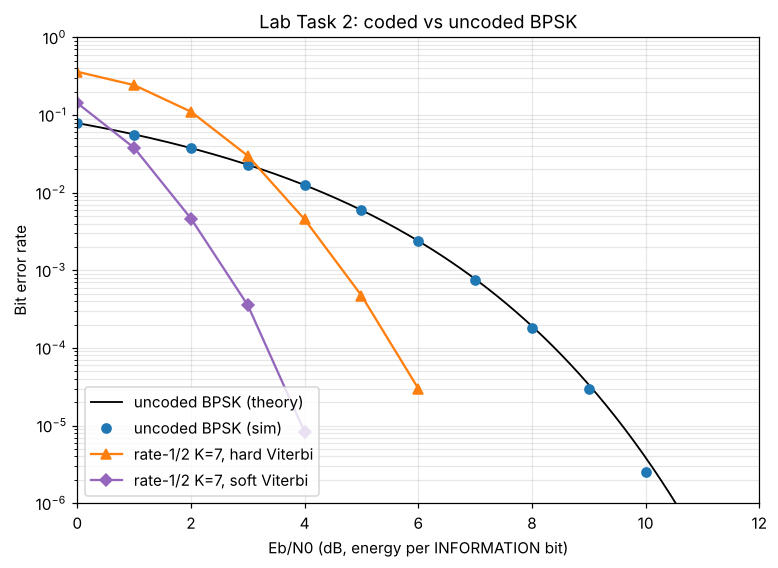

 Eb/N0 | uncoded BPSK | hard Viterbi | soft Viterbi
   0 dB |    7.86e-02  |    3.61e-01  |    1.42e-01
   1 dB |    5.63e-02  |    2.43e-01  |    3.78e-02
   2 dB |    3.75e-02  |    1.10e-01  |    4.64e-03
   3 dB |    2.29e-02  |    2.98e-02  |    3.55e-04
   4 dB |    1.25e-02  |    4.53e-03  |    8.33e-06
   5 dB |    5.95e-03  |    4.73e-04  |    0.00e+00
   6 dB |    2.39e-03  |    3.00e-05  |    0.00e+00
   7 dB |    7.73e-04  |    0.00e+00  |    0.00e+00
   8 dB |    1.91e-04  |    0.00e+00  |    0.00e+00

BER 0.001: uncoded 6.80 dB, hard 4.67 dB, soft 2.60 dB
  coding gain: hard-decision 2.13 dB, soft-decision 4.20 dB

BER 0.0001: uncoded 8.40 dB, hard 5.56 dB, soft 3.34 dB
  coding gain: hard-decision 2.84 dB, soft-decision 5.06 dB


In [13]:
K, G = 7, (0o171, 0o133)
NS = 2**(K-1)                                   # 64 trellis states

def parity(x):
    return np.array([bin(v).count("1") & 1 for v in np.atleast_1d(x)])

# trellis tables: register = (u << (K-1)) | state, next_state = register >> 1
states = np.arange(NS)
OUT = np.zeros((NS, 2, 2), dtype=int)           # OUT[state, u] -> (c0, c1)
NEXT = np.zeros((NS, 2), dtype=int)
for u in (0, 1):
    reg = (u << (K-1)) | states
    NEXT[:, u] = reg >> 1
    OUT[:, u, 0] = parity(reg & G[0])
    OUT[:, u, 1] = parity(reg & G[1])

def conv_encode(frames):
    # frames: (F, L) info bits -> (F, 2*(L+K-1)) coded bits, each frame zero-terminated.
    F, L = frames.shape
    u_all = np.concatenate([frames, np.zeros((F, K-1), int)], axis=1)
    s = np.zeros(F, int)
    out = np.empty((F, 2*u_all.shape[1]), int)
    for t in range(u_all.shape[1]):
        u = u_all[:, t]
        out[:, 2*t] = OUT[s, u, 0]
        out[:, 2*t+1] = OUT[s, u, 1]
        s = NEXT[s, u]
    return out

# for every next state ns: input bit u = ns >> (K-2); predecessors ps = ((ns mod 2^(K-2)) << 1) | b, b in {0,1}
ns = states
U_NS = ns >> (K-2)
PRED = np.stack([((ns & (2**(K-2)-1)) << 1) | b for b in (0, 1)])        # (2, NS)
EXP = np.stack([2*OUT[PRED[b], U_NS, :] - 1 for b in (0, 1)])              # (2, NS, 2) expected +/-1

def viterbi_decode(r, L):
    # r: (F, 2*(L+K-1)) real soft values (+ means bit 1). Maximum-correlation Viterbi. Returns (F, L) bits.
    F = r.shape[0]; T = r.shape[1]//2
    pm = np.full((F, NS), -1e18); pm[:, 0] = 0.0
    dec = np.empty((T, F, NS), dtype=np.uint8)
    for t in range(T):
        r0, r1 = r[:, 2*t, None], r[:, 2*t+1, None]
        c0 = pm[:, PRED[0]] + r0*EXP[0, :, 0] + r1*EXP[0, :, 1]
        c1 = pm[:, PRED[1]] + r0*EXP[1, :, 0] + r1*EXP[1, :, 1]
        pick = c1 > c0
        dec[t] = pick
        pm = np.where(pick, c1, c0)
        pm -= pm.max(axis=1, keepdims=True)          # keep metrics bounded
    s = np.zeros(F, int)                              # terminated -> end in state 0
    u_hat = np.empty((F, T), int)
    fr = np.arange(F)
    for t in range(T-1, -1, -1):
        u_hat[:, t] = s >> (K-2)
        b = dec[t, fr, s]
        s = ((s & (2**(K-2)-1)) << 1) | b
    return u_hat[:, :L]

# self-check: noiseless encode -> decode is lossless
chk = np.random.randint(0, 2, (5, 50))
assert np.array_equal(viterbi_decode(2.0*conv_encode(chk)-1, 50), chk)
print("Noiseless encode/decode round trip: OK")

L_frame, F_frames = 400, 1500                      # 600,000 info bits per Eb/N0 point
info = np.random.randint(0, 2, (F_frames, L_frame))
coded = conv_encode(info)
R = 0.5
EbN0_code = np.arange(0, 9, 1)
ber_hard, ber_soft = [], []
for e in EbN0_code:
    tx = 2.0*coded - 1                              # BPSK on coded bits, Ec = 1
    N0 = 1.0/(R*10**(e/10))                         # Eb = Ec/R = 2  ->  N0 = Eb/(Eb/N0)
    rx = tx + np.sqrt(N0/2)*np.random.randn(*tx.shape)
    ber_soft.append(np.mean(viterbi_decode(rx, L_frame) != info))
    ber_hard.append(np.mean(viterbi_decode(np.sign(rx), L_frame) != info))
ber_hard, ber_soft = np.array(ber_hard), np.array(ber_soft)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.semilogy(Efine, ber_bpsk_theory(Efine), "k-", lw=1.2, label="uncoded BPSK (theory)")
plot_ber(ax, EbN0_dB, ber_bpsk, marker="o", ls="none", color="tab:blue", label="uncoded BPSK (sim)")
plot_ber(ax, EbN0_code, ber_hard, marker="^", ls="-", color="tab:orange", label="rate-1/2 K=7, hard Viterbi")
plot_ber(ax, EbN0_code, ber_soft, marker="D", ls="-", color="tab:purple", label="rate-1/2 K=7, soft Viterbi")
ax.set_ylim(1e-6, 1); ax.set_xlim(0, 12); ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("Eb/N0 (dB, energy per INFORMATION bit)"); ax.set_ylabel("Bit error rate")
ax.set_title("Lab Task 2: coded vs uncoded BPSK"); ax.legend(loc="lower left")
plt.savefig(f"{FIG_DIR}/task2_coding_gain.png", bbox_inches="tight"); plt.show()

print(" Eb/N0 | uncoded BPSK | hard Viterbi | soft Viterbi")
for i, e in enumerate(EbN0_code):
    print(f"  {e:>2} dB | {ber_bpsk_theory(e):11.2e}  | {ber_hard[i]:11.2e}  | {ber_soft[i]:11.2e}")
for tgt in (1e-3, 1e-4):
    e_unc = Efine[np.argmin(abs(np.log10(ber_bpsk_theory(Efine)) - np.log10(tgt)))]
    e_h = ebn0_at_ber(EbN0_code, ber_hard, tgt)
    e_s = ebn0_at_ber(EbN0_code, ber_soft, tgt)
    print(f"\nBER {tgt:g}: uncoded {e_unc:.2f} dB, hard {e_h:.2f} dB, soft {e_s:.2f} dB")
    print(f"  coding gain: hard-decision {e_unc-e_h:.2f} dB, soft-decision {e_unc-e_s:.2f} dB")

**Interpretation.** At very low Eb/N0 the coded curves are *worse* than uncoded BPSK. The individual coded bits have only half the energy,
and the decoder makes error bursts once too many bits are wrong. Above a crossover point the code corrects almost everything and the curve drops much more steeply.
Soft decisions gain roughly 2 dB more than hard decisions because they keep the reliability information that hard slicing throws away.
This is the practical way systems move toward the Shannon limit described in Step 14.

### Lab Task 3 — 64-QAM and the growing Eb/N0 gap

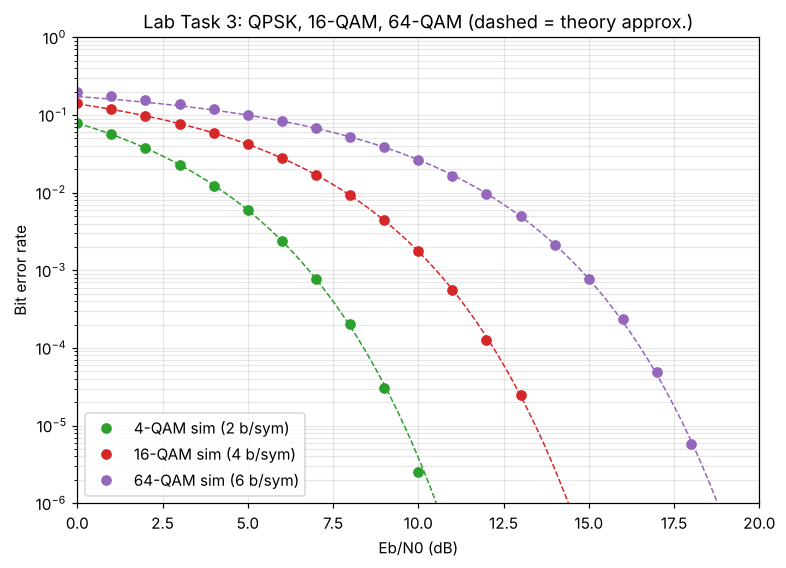

  scheme | b/s/Hz | Eb/N0 @1e-3 | SNR @1e-3 | Shannon min SNR | gap to Shannon (SNR)
    BPSK |      1 |     6.75 dB |   6.75 dB |         0.00 dB |     6.75 dB
    QPSK |      2 |     6.78 dB |   9.79 dB |         4.77 dB |     5.02 dB
  16-QAM |      4 |    10.49 dB |  16.51 dB |        11.76 dB |     4.75 dB
  64-QAM |      6 |    14.75 dB |  22.53 dB |        17.99 dB |     4.54 dB

Extra Eb/N0 per step: QPSK->16-QAM 3.72 dB, 16-QAM->64-QAM 4.26 dB
Extra SNR   per step: QPSK->16-QAM 6.73 dB, 16-QAM->64-QAM 6.02 dB


In [14]:
EbN0_wide = np.arange(0, 21, 1)
ber_64 = simulate_ber(64, EbN0_wide, bits)
ber_16w = simulate_ber(16, EbN0_wide, bits)
ber_4w = simulate_ber(4, EbN0_wide, bits)

fig, ax = plt.subplots(figsize=(8, 5.5))
Ew = np.linspace(0, 20, 300)
for M, b, c in [(4, ber_4w, "tab:green"), (16, ber_16w, "tab:red"), (64, ber_64, "tab:purple")]:
    ax.semilogy(Ew, ber_mqam_theory(Ew, M), "--", color=c, lw=1)
    plot_ber(ax, EbN0_wide, b, marker="o", ls="none", color=c, label=f"{M}-QAM sim ({int(np.log2(M))} b/sym)")
ax.set_ylim(1e-6, 1); ax.set_xlim(0, 20); ax.grid(True, which="both", alpha=0.3)
ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel("Bit error rate"); ax.legend(loc="lower left")
ax.set_title("Lab Task 3: QPSK, 16-QAM, 64-QAM (dashed = theory approx.)")
plt.savefig(f"{FIG_DIR}/task3_64qam.png", bbox_inches="tight"); plt.show()

print(f"{'scheme':>8} | b/s/Hz | Eb/N0 @1e-3 | SNR @1e-3 | Shannon min SNR | gap to Shannon (SNR)")
rows = []
for M, b in [(2, ber_bpsk), (4, ber_4w), (16, ber_16w), (64, ber_64)]:
    k = int(np.log2(M))
    e = ebn0_at_ber(EbN0_dB if M == 2 else EbN0_wide, b)
    snr = e + 10*np.log10(k)
    smin = 10*np.log10(2.0**k - 1)
    rows.append((M, k, e, snr))
    name = {2: "BPSK", 4: "QPSK"}.get(M, f"{M}-QAM")
    print(f"{name:>8} | {k:>6} | {e:8.2f} dB | {snr:6.2f} dB | {smin:12.2f} dB | {snr-smin:8.2f} dB")
print(f"\nExtra Eb/N0 per step: QPSK->16-QAM {rows[2][2]-rows[1][2]:.2f} dB, 16-QAM->64-QAM {rows[3][2]-rows[2][2]:.2f} dB")
print(f"Extra SNR   per step: QPSK->16-QAM {rows[2][3]-rows[1][3]:.2f} dB, 16-QAM->64-QAM {rows[3][3]-rows[2][3]:.2f} dB")

**Relation to the log term in Shannon–Hartley.** Each step from QPSK to 16-QAM to 64-QAM adds 2 bits/symbol.
Because $C \propto \log_2(1+\text{SNR})$, every extra bit per channel use roughly **doubles** the SNR needed (+3 dB per bit at high SNR, so +6 dB per 2-bit step).
The simulation shows +6.8 dB and +5.9 dB of SNR for the two steps, close to that rule. In Eb/N0 terms the gap also grows (≈3.8 dB, then ≈4.2 dB),
and the gap to the Shannon limit stays at roughly 4.5–5 dB for every QAM order, so each denser constellation "pays" the full logarithmic price that the theorem sets.
Spectral efficiency grows only linearly while the required power grows exponentially, which is the same diminishing return that the logarithm in Shannon–Hartley expresses.

### Lab Task 4 — log-distance path loss with exponent n = 2 … 4
$PL(d) = PL(d_0) + 10\,n\,\log_{10}(d/d_0)$. The reference loss $PL(d_0)$ at $d_0 = 100$ m is taken from free space (Friis) at 1900 MHz, with the same link budget as Part (a).

PL(d0 = 100 m, 1900 MHz) = 78.02 dB (free space)


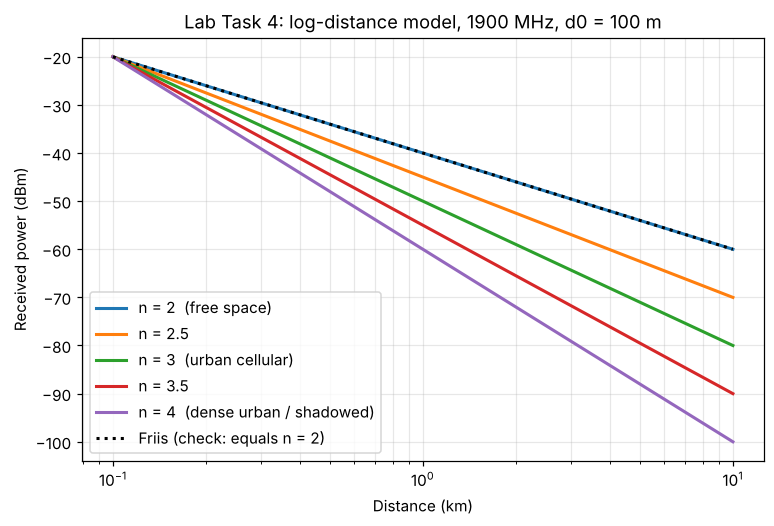

n=2: P_RX at 1 km =  -40.02 dBm, at 10 km =  -60.02 dBm (loss per distance doubling = 6.02 dB)
n=3: P_RX at 1 km =  -50.02 dBm, at 10 km =  -80.02 dBm (loss per distance doubling = 9.03 dB)
n=4: P_RX at 1 km =  -60.02 dBm, at 10 km = -100.02 dBm (loss per distance doubling = 12.04 dB)


In [15]:
f_ref = 1900                     # MHz
d0 = 0.1                         # km
PL_d0 = 20*np.log10(d0) + 20*np.log10(f_ref) + 32.44
print(f"PL(d0 = {d0*1000:.0f} m, {f_ref} MHz) = {PL_d0:.2f} dB (free space)")

def log_distance_rx(d_km, n, Ptx=Ptx_dBm, Gt=Gtx_dBi, Gr=Grx_dBi):
    return Ptx + Gt + Gr - (PL_d0 + 10*n*np.log10(d_km/d0))

dd = np.linspace(d0, 10, 500)
fig, ax = plt.subplots(figsize=(8, 5))
for n, env in [(2, "free space"), (2.5, ""), (3, "urban cellular"), (3.5, ""), (4, "dense urban / shadowed")]:
    ax.semilogx(dd, log_distance_rx(dd, n), lw=2, label=f"n = {n}" + (f"  ({env})" if env else ""))
ax.semilogx(dd, friis_rx_power(Ptx_dBm, Gtx_dBi, Grx_dBi, dd, f_ref), "k:", lw=2, label="Friis (check: equals n = 2)")
ax.set_xlabel("Distance (km)"); ax.set_ylabel("Received power (dBm)"); ax.legend()
ax.set_title(f"Lab Task 4: log-distance model, {f_ref} MHz, d0 = 100 m"); ax.grid(True, which="both", alpha=0.3)
plt.savefig(f"{FIG_DIR}/task4_log_distance.png", bbox_inches="tight"); plt.show()

for n in [2, 3, 4]:
    print(f"n={n}: P_RX at 1 km = {log_distance_rx(1, n):7.2f} dBm, at 10 km = {log_distance_rx(10, n):7.2f} dBm "
          f"(loss per distance doubling = {10*n*np.log10(2):.2f} dB)")

### Lab Task 5 — add log-normal shadowing (σ = 4 dB and 8 dB)
A zero-mean Gaussian random variable in dB, $X_\sigma$, is added to Task 4's model with $n = 3$: $P_{RX} = \overline{P}_{RX}(d) + X_\sigma$.
Each realization draws an independent value at every distance. That gives the scatter view; real shadowing is spatially correlated over tens of metres.

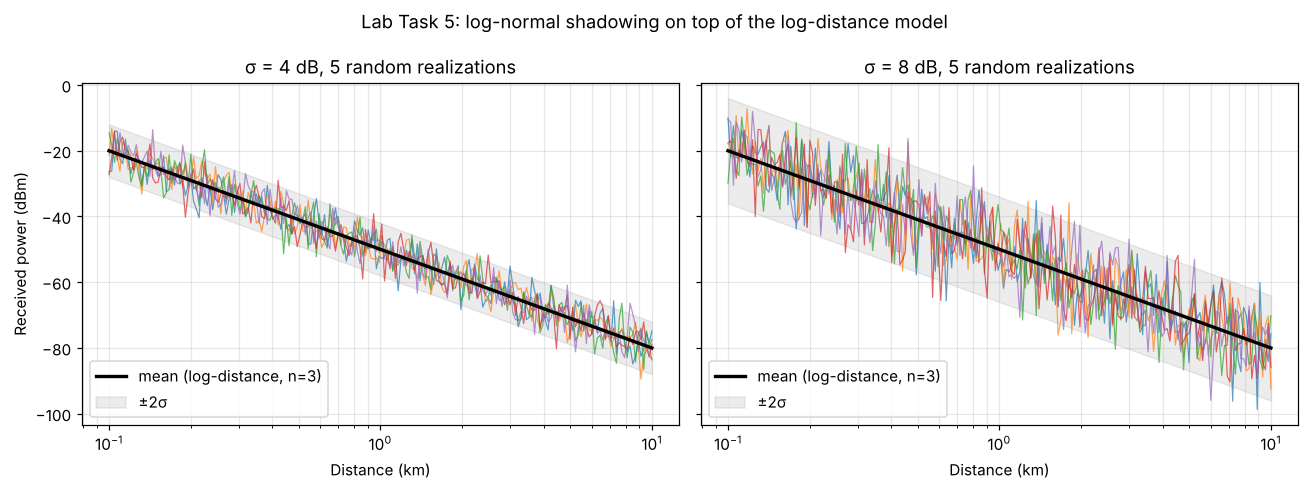

σ=4 dB: mean P_RX(5 km) = -71.0 dBm, P(P_RX > -75 dBm) = 0.842, fade margin for 90 % reliability = 5.1 dB
σ=8 dB: mean P_RX(5 km) = -71.0 dBm, P(P_RX > -75 dBm) = 0.692, fade margin for 90 % reliability = 10.3 dB

Without shadowing the 5 km point would ALWAYS be 4 dB above the threshold. With shadowing it fails
a noticeable fraction of the time, which is why link budgets add a shadowing fade margin.


In [16]:
n_sh = 3
dd_s = np.logspace(np.log10(d0), 1, 200)
mean_rx = log_distance_rx(dd_s, n_sh)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, sigma in zip(axes, [4, 8]):
    for r_ in range(5):
        ax.semilogx(dd_s, mean_rx + sigma*np.random.randn(dd_s.size), lw=0.8, alpha=0.7)
    ax.semilogx(dd_s, mean_rx, "k-", lw=2.2, label="mean (log-distance, n=3)")
    ax.fill_between(dd_s, mean_rx - 2*sigma, mean_rx + 2*sigma, color="gray", alpha=0.15, label="±2σ")
    ax.set_title(f"σ = {sigma} dB, 5 random realizations"); ax.set_xlabel("Distance (km)")
    ax.legend(loc="lower left"); ax.grid(True, which="both", alpha=0.3)
axes[0].set_ylabel("Received power (dBm)")
fig.suptitle("Lab Task 5: log-normal shadowing on top of the log-distance model")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/task5_shadowing.png", bbox_inches="tight"); plt.show()

# practical consequence: probability the received power stays above a -75 dBm receiver threshold at 5 km,
# and the fade margin needed for 90 % location reliability (z = 1.2816)
thr = -75
from scipy.stats import norm
for sigma in [4, 8]:
    p = 1 - norm.cdf(thr, loc=log_distance_rx(5, n_sh), scale=sigma)
    print(f"σ={sigma} dB: mean P_RX(5 km) = {log_distance_rx(5, n_sh):.1f} dBm, "
          f"P(P_RX > {thr} dBm) = {p:.3f}, fade margin for 90 % reliability = {norm.ppf(0.9)*sigma:.1f} dB")
print("\nWithout shadowing the 5 km point would ALWAYS be 4 dB above the threshold. With shadowing it fails")
print("a noticeable fraction of the time, which is why link budgets add a shadowing fade margin.")

### Lab Task 6 — throughput proxy vs Shannon–Hartley capacity
The manual's proxy is throughput ≈ $k\,(1-\text{BER})$ bits per symbol (≈ b/s/Hz with Nyquist signalling, one symbol per Hz).
To compare schemes fairly, every curve is plotted against the same **SNR per symbol** $E_s/N_0$, together with $C/B = \log_2(1+\text{SNR})$.
Each scheme is re-simulated on a common SNR grid from −2 to 30 dB so that no curve has to be extrapolated.

A second, corrected proxy is also plotted, $k\,[1 - H_2(\text{BER})]$, where $H_2(p) = -p\log_2 p - (1-p)\log_2(1-p)$.
The reason for it is shown below.

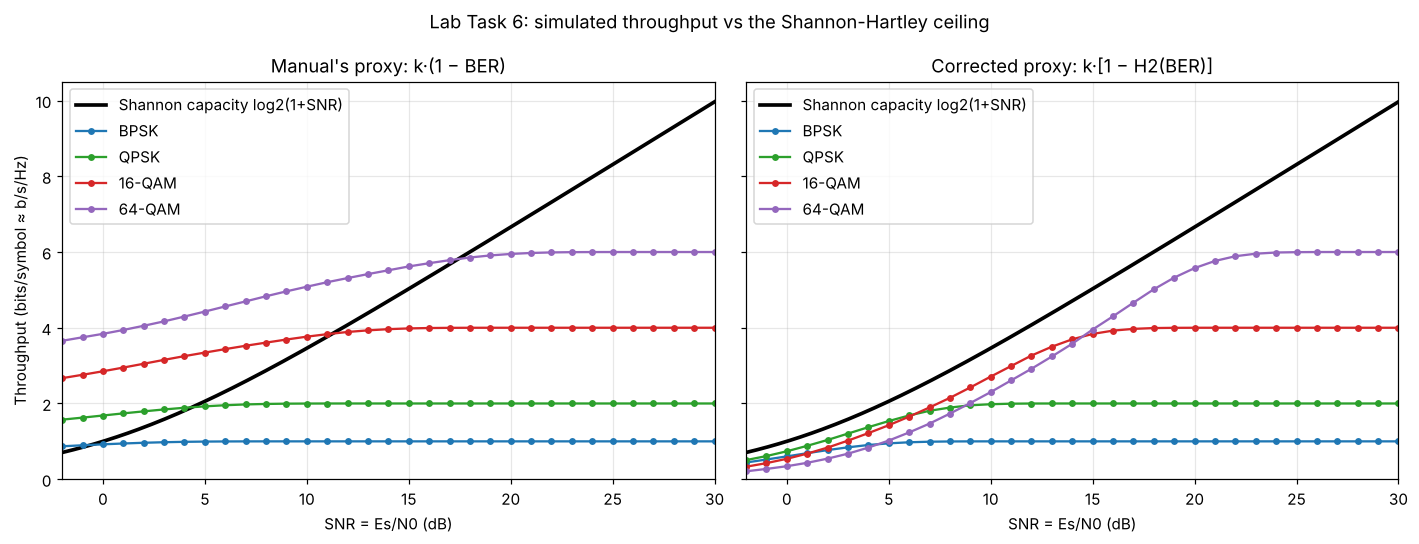

SNR | Shannon C/B |  k(1-BER) per scheme                 |  k[1-H2(BER)] per scheme
dB  |             |  BPSK   QPSK  16QAM  64QAM            |  BPSK   QPSK  16QAM  64QAM
  0 |     1.00    |  0.92  1.68  2.85  3.84              |  0.60  0.74  0.54  0.34
  5 |     2.06    |  0.99  1.92  3.34  4.43              |  0.95  1.54  1.43  1.02
 10 |     3.46    |  1.00  2.00  3.76  5.08              |  1.00  1.98  2.71  2.30
 15 |     5.03    |  1.00  2.00  3.98  5.62              |  1.00  2.00  3.84  3.95
 20 |     6.66    |  1.00  2.00  4.00  5.95              |  1.00  2.00  4.00  5.58
 25 |     8.31    |  1.00  2.00  4.00  6.00              |  1.00  2.00  4.00  6.00
 30 |     9.97    |  1.00  2.00  4.00  6.00              |  1.00  2.00  4.00  6.00

Points where k(1-BER) EXCEEDS the Shannon capacity: 43 (e.g. [('BPSK', -2), ('BPSK', -1), ('QPSK', -2), ('QPSK', -1)])
Points where k[1-H2(BER)] exceeds the Shannon capacity: 0


In [17]:
def H2(p):
    p = np.clip(p, 1e-15, 0.5)
    return -p*np.log2(p) - (1-p)*np.log2(1-p)

snr_grid = np.arange(-2, 31, 1)
schemes = [("BPSK", "BPSK", 1, "tab:blue"), ("QPSK", 4, 2, "tab:green"),
           ("16-QAM", 16, 4, "tab:red"), ("64-QAM", 64, 6, "tab:purple")]
ber_snr = {name: simulate_ber(sch, snr_grid - 10*np.log10(k), bits) for name, sch, k, _ in schemes}

snr_axis = np.linspace(-2, 30, 300)
cap = np.log2(1 + 10**(snr_axis/10))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, title, f in [(axes[0], "Manual's proxy: k·(1 − BER)", lambda k, b: k*(1-b)),
                     (axes[1], "Corrected proxy: k·[1 − H2(BER)]", lambda k, b: k*(1-H2(b)))]:
    ax.plot(snr_axis, cap, "k-", lw=2.4, label="Shannon capacity log2(1+SNR)")
    for name, sch, k, c in schemes:
        ax.plot(snr_grid, f(k, ber_snr[name]), "o-", ms=3.5, color=c, label=name)
    ax.set_title(title); ax.set_xlabel("SNR = Es/N0 (dB)"); ax.set_xlim(-2, 30); ax.set_ylim(0, 10.5)
    ax.legend(loc="upper left")
axes[0].set_ylabel("Throughput (bits/symbol ≈ b/s/Hz)")
fig.suptitle("Lab Task 6: simulated throughput vs the Shannon-Hartley ceiling")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/task6_throughput_vs_shannon.png", bbox_inches="tight"); plt.show()

print("SNR | Shannon C/B |  k(1-BER) per scheme                 |  k[1-H2(BER)] per scheme")
print("dB  |             |  BPSK   QPSK  16QAM  64QAM            |  BPSK   QPSK  16QAM  64QAM")
for s_ in [0, 5, 10, 15, 20, 25, 30]:
    i = int(np.where(snr_grid == s_)[0][0])
    raw = [k*(1-ber_snr[n][i]) for n, _, k, _ in schemes]
    cor = [k*(1-H2(ber_snr[n][i])) for n, _, k, _ in schemes]
    print(f"{s_:>3} |   {np.log2(1+10**(s_/10)):6.2f}    | " + " ".join(f"{v:5.2f}" for v in raw)
          + "              | " + " ".join(f"{v:5.2f}" for v in cor))

viol = [(n, int(s_)) for n, _, k, _ in schemes for s_, b in zip(snr_grid, ber_snr[n])
        if k*(1-b) > np.log2(1+10**(s_/10)) + 1e-9]
print(f"\nPoints where k(1-BER) EXCEEDS the Shannon capacity: {len(viol)} (e.g. {viol[:4]})")
viol2 = [(n, s_) for n, _, k, _ in schemes for s_, b in zip(snr_grid, ber_snr[n])
         if k*(1-H2(b)) > np.log2(1+10**(s_/10)) + 1e-9]
print(f"Points where k[1-H2(BER)] exceeds the Shannon capacity: {len(viol2)}")

**Qualitative comparison and a warning about the proxy.**

*Left plot (the manual's proxy).* At high SNR every scheme saturates at its $k$ bits/symbol, and the envelope over schemes, which is what adaptive
modulation would pick, rises in steps with the same logarithmic shape as the capacity curve while trailing it by several dB.
At **low SNR, however, $k(1-\text{BER})$ climbs above the Shannon ceiling** (the printout counts the points). That is impossible for a real link.
The cause is that $1-\text{BER}$ never falls below 0.5: even a receiver that guesses at random gets half its bits right, so the proxy credits
"throughput" made only of lucky guesses. The proxy is fine at high SNR, where BER ≈ 0, but meaningless when BER is large.

*Right plot (corrected).* $k[1-H_2(\text{BER})]$ is the information rate that can actually be recovered from hard bit decisions with an
ideal outer error-correcting code. It goes to 0 when BER → 0.5 and to $k$ when BER → 0, and **every point now lies below the Shannon curve**, as the theorem requires.
The remaining gap of a few dB is the price of hard, symbol-by-symbol decisions and of a fixed square constellation.
Each step up in constellation size adds less to throughput than the previous one for the same SNR increase, which is the logarithmic law of Shannon–Hartley seen in data.

## 6. Deliverable checklist

| Required by the manual | Where in this notebook |
|---|---|
| Friis path loss vs distance, ≥ 3 frequencies | Section 2, Step 4 plot (900 / 1900 / 3500 MHz) |
| 6 dB-per-doubling check printed as output | Section 2, Step 5 output |
| Combined BPSK / 16-QAM BER vs Eb/N0, log y-axis, theoretical BPSK overlaid | Section 3, Step 12 plot |
| Stated numeric SNR gap at a chosen target BER | Section 4 output (BER = 10⁻³) |
| Short paragraph explaining the gap via Shannon–Hartley | Section 4, Step 14 |
| Lab Tasks 1–6 | Section 5 |

All figures are also saved as PNG files in `figures_2_1/`.

In [18]:
print(sorted(os.listdir(FIG_DIR)))

['16qam_gray_constellation.png', 'ber_bpsk_vs_16qam.png', 'friis_rx_power_vs_distance.png', 'task1_qpsk.png', 'task2_coding_gain.png', 'task3_64qam.png', 'task4_log_distance.png', 'task5_shadowing.png', 'task6_throughput_vs_shannon.png']
